# 12 · Tests, diagnostics and benchmark

The generator never runs tests or checks on its own. They are separate, and you run them when you
want them:

| what | where | needs |
|---|---|---|
| unit tests | `tests/run_tests.py` (or `pytest tests/`) | nothing (small phantoms), CPU or GPU |
| diagnostics | `nxgen/checks.py` | any generated volume |
| benchmark | `tests/benchmark.py` | real templates, GPU |
| figures | `examples/plot_steps.py` | real templates |

In [1]:
from _setup import *
import subprocess
PY = sys.executable

## 1. The unit tests

```bash
python tests/run_tests.py                    # all, CPU (~10 s)
python tests/run_tests.py --device cuda:0    # tests with a `device` argument run on the GPU
python tests/run_tests.py -k spatial         # only names containing 'spatial'
python tests/run_tests.py -x                 # stop at the first failure
```

In [2]:
r = subprocess.run([PY, 'tests/run_tests.py'], cwd=ROOT, capture_output=True, text=True)
lines = [l for l in r.stdout.splitlines() if l.startswith(('PASSED', 'FAILED', 'SKIPPED'))]
print('\n'.join(lines))
print(r.stdout.strip().splitlines()[-1])

PASSED     0.00s  test_core::test_bspline_convex_and_patch_consistent
PASSED     0.00s  test_core::test_config_defaults_and_overrides
PASSED     0.00s  test_core::test_config_rejects_unknown_and_invalid
PASSED     0.00s  test_core::test_config_relative_tree_path
PASSED     0.00s  test_core::test_draw_specs
PASSED     0.00s  test_core::test_label_space
PASSED     0.00s  test_core::test_seeds_independent_and_reproducible
PASSED     0.03s  test_geometry_modules::test_acquisition_priors
PASSED     0.02s  test_geometry_modules::test_morphology_grows_only_into_the_other_group
PASSED     0.02s  test_geometry_modules::test_morphology_on_crop_equals_full
PASSED     0.09s  test_geometry_modules::test_pv_downsample_mass_and_majority
PASSED     0.01s  test_geometry_modules::test_pv_factor_one_is_hard_labels
PASSED     0.83s  test_geometry_modules::test_pv_smooth_keeps_seg_and_mixes_boundaries
PASSED     0.00s  test_geometry_modules::test_pv_topk_truncation_reports_lost_mass
PASSED     0.01s  test_

What each file tests:

| file | tests |
|---|---|
| `test_core.py` | config (defaults, unknown keys, invalid values, relative paths), distribution specs, seeds, label space, B-spline fields (convex, patch-consistent) |
| `test_template.py` | super-resolution identity, no new labels, volumes kept, crop/padding, restriction, record + cache, **bit-exact equality with v2** |
| `test_geometry_modules.py` | acquisition priors; morphology (only the shrinking group changes, crop + halo == full); spatial (identity, patch == crop, 180° == flip); partial volume (factor 1, mass conservation, majority vs brute force, truncation, smooth) |
| `test_intensity_modules.py` | tree (collapse, per-contrast r_max, same values at any resolution, null nodes, min_sigma); synthesis (pure voxels follow the Gaussians, same class shares noise); bias (range, patch == crop); motion (identity, effect, rigid); resolution (shapes, low-res noise, **close to v2**); noise; normalisation |
| `test_pipeline.py` | shapes/ranges, same plan → same output, JSON replay, independent module streams, patch == crop of full volume, recorder, plan editing, both CLIs, training stream |

The two v2 equivalence tests import `../generator_v2/tree_generator.py`; they are skipped (not
failed) if it cannot be imported.

### Writing a test

A test is a function `test_<name>()` in a `tests/test_*.py` file with plain `assert`s. Add a
`device='cpu'` argument to run it on the device given to `run_tests.py`; raise
`phantoms.Skip('reason')` when an optional dependency is missing. The phantoms
(`tests/phantoms.py`) give a small tree, a spherical label map and a ready `Generator`:

phantom generator: 5 labels, factor 2 | patch (8, 8, 8)


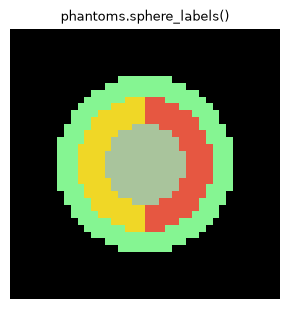

In [3]:
import phantoms
g = phantoms.generator(DEVICE, patch={'size': [8, 8, 8]})
s = g(0)
print('phantom generator:', len(g.labels), 'labels, factor', g.factor, '| patch', tuple(s.seg.shape))
show([phantoms.sphere_labels()], ['phantoms.sphere_labels()'], labels=[True])

## 2. Diagnostics: `nxgen.checks`

Functions for any volume (e.g. the steps kept by a `Recorder`):

| function | returns |
|---|---|
| `labels_present(lab)`, `label_volumes(lab)` | labels in a map, voxels per label |
| `new_labels(before, after)`, `vanished_labels(before, after)` | labels that appeared / disappeared |
| `contacts(lab, a, b)` | voxel faces between two groups of indices |
| `adjacency_violations(lab, rules, label_space, tree)` | contacts for each forbidden pair of groups |
| `gaussian_fit_pure(image, pv, tree_params)` | per-label intensity statistics on pure voxels (notebook 08) |

In [4]:
from nxgen import Generator, Recorder, checks
from nxgen.core.config import load_config
ensure_template()
gen = Generator([TEMPLATE], load_config(CONFIG, morphology={'prob': 1.0}), device=DEVICE)
rec = Recorder(steps=['template_crop', 'morphology', 'spatial'])
s = gen(3, recorder=rec)

tpl = rec.steps['template_crop']
print('labels vanished by morphology      :', checks.vanished_labels(tpl, rec.steps['morphology']))
print('labels vanished by the whole chain :', [(i, gen.labels.names[i]) for i in checks.vanished_labels(tpl, s.seg.cpu())])
print('new labels (must be none)          :', checks.new_labels(tpl, s.seg.cpu()))

labels vanished by morphology      : [42]
labels vanished by the whole chain : [(42, 'supraoptic_dicussation')]
new labels (must be none)          : []


Small structures can vanish when the deformation zooms out and the 2×2×2 majority vote loses
them. This is information, not an error. Repeat over many seeds to see how often each label
survives.

### Adjacency rules

The initial proposal suggested checking that CSF never touches WM (GM should lie between them).
`adjacency_violations` counts the contacts for any pair of groups:

In [5]:
rules = [['cerebral_wm_l1', 'csf_ventricles_l1'], ['cerebral_wm_l1', 'background_l1'],
         ['cerebellar_wm_l1', 'background_l1']]
# baseline: the same image without morphology and deformation, on the same 0.4 mm grid
# (counting on the 0.2 mm template would not be comparable: faces scale with the grid)
base = gen.render(dict(s.plan, morphology=None, spatial=None)).seg
base_v = checks.adjacency_violations(base, rules, gen.labels, gen.tree)
out_v = checks.adjacency_violations(s.seg, rules, gen.labels, gen.tree)
for rule in base_v:
    print(f'{rule:40s} undeformed {base_v[rule]:6d} faces | generated {out_v[rule]:6d} faces '
          f'({out_v[rule] / max(base_v[rule], 1):.2f}x)')
print('morphology of this image:', [(o['grow'], o['shrink'], o['n_iter']) for o in s.plan['morphology']['ops']])

cerebral_wm_l1|csf_ventricles_l1         undeformed  47181 faces | generated  29910 faces (0.63x)
cerebral_wm_l1|background_l1             undeformed  15198 faces | generated  19163 faces (1.26x)
cerebellar_wm_l1|background_l1           undeformed   4853 faces | generated   4128 faces (0.85x)
morphology of this image: [('cerebral_gm_l1', 'background_l1', 2), ('background_l1', 'cerebellar_gm_l1', 2), ('cerebral_wm_l1', 'cerebral_gm_l1', 3), ('cerebellar_gm_l1', 'cerebellar_wm_l1', 2), ('cerebral_wm_l1', 'csf_ventricles_l1', 3), ('deep_gm_l1', 'cerebral_wm_l1', 2)]


WM–ventricle contact is real anatomy (the ventricles are surrounded by white matter), so that rule
can only apply to external CSF. In this NextBrain map, sulcal CSF is labelled background, so a
WM–background rule is the closer check for "the cortex disappeared between WM and CSF". The
counts without shape changes are the baseline; a generated image far above it means a morphology
pair ate through a structure (e.g. WM growing into GM until it reaches the background).

## 3. Benchmark

```bash
python tests/benchmark.py --templates data/templates --config configs/nextbrain.json \
    --device cuda:0 -n 5 [--patch 160 160 160] [--worst-case]
```

Median time and peak GPU memory of every step. `--worst-case` forces motion and a degraded
acquisition.

In [6]:
for extra in ([], ['--patch', '160', '160', '160']):
    r = subprocess.run([PY, 'tests/benchmark.py', '--templates', TEMPLATE_DIR, '--config', CONFIG,
                        '--device', DEVICE, '-n', '4', '--worst-case'] + extra,
                       cwd=ROOT, capture_output=True, text=True)
    print(r.stdout, r.stderr[-1000:])

300 labels, factor 2, output voxel 0.4 mm, patch full volume
  seed 1: 0.286 s, shape [239, 439, 289], motion True, acquisition aniso
  seed 2: 0.391 s, shape [239, 439, 289], motion True, acquisition aniso
  seed 3: 0.404 s, shape [239, 439, 289], motion True, acquisition iso
  seed 4: 0.385 s, shape [239, 439, 289], motion True, acquisition aniso

step              median s  max peak GB
crop                 0.000         0.70
morphology           0.103         7.01
spatial              0.048         2.89
partial_volume       0.180         3.19
synthesis            0.025         4.43
bias                 0.001         1.13
motion               0.015         2.22
resolution           0.006         1.25
normalization        0.000         1.22
total                0.388   (without profiling syncs it is slightly faster)
 
300 labels, factor 2, output voxel 0.4 mm, patch [160, 160, 160]
  seed 1: 0.047 s, shape [160, 160, 160], motion True, acquisition aniso
  seed 2: 0.068 s, shape [160, 

## 4. Figures of every step

```bash
python examples/plot_steps.py --templates data/templates --config configs/nextbrain.json \
    --device cuda:0 --seeds 0 1 2 --out data/outputs/steps.png [--worst-case]
```

saved /home/agustin/phd/synthseg_nextbrain/project/dev/wp3/generator_v2_modular/data/outputs/notebooks/steps_notebook.png
 


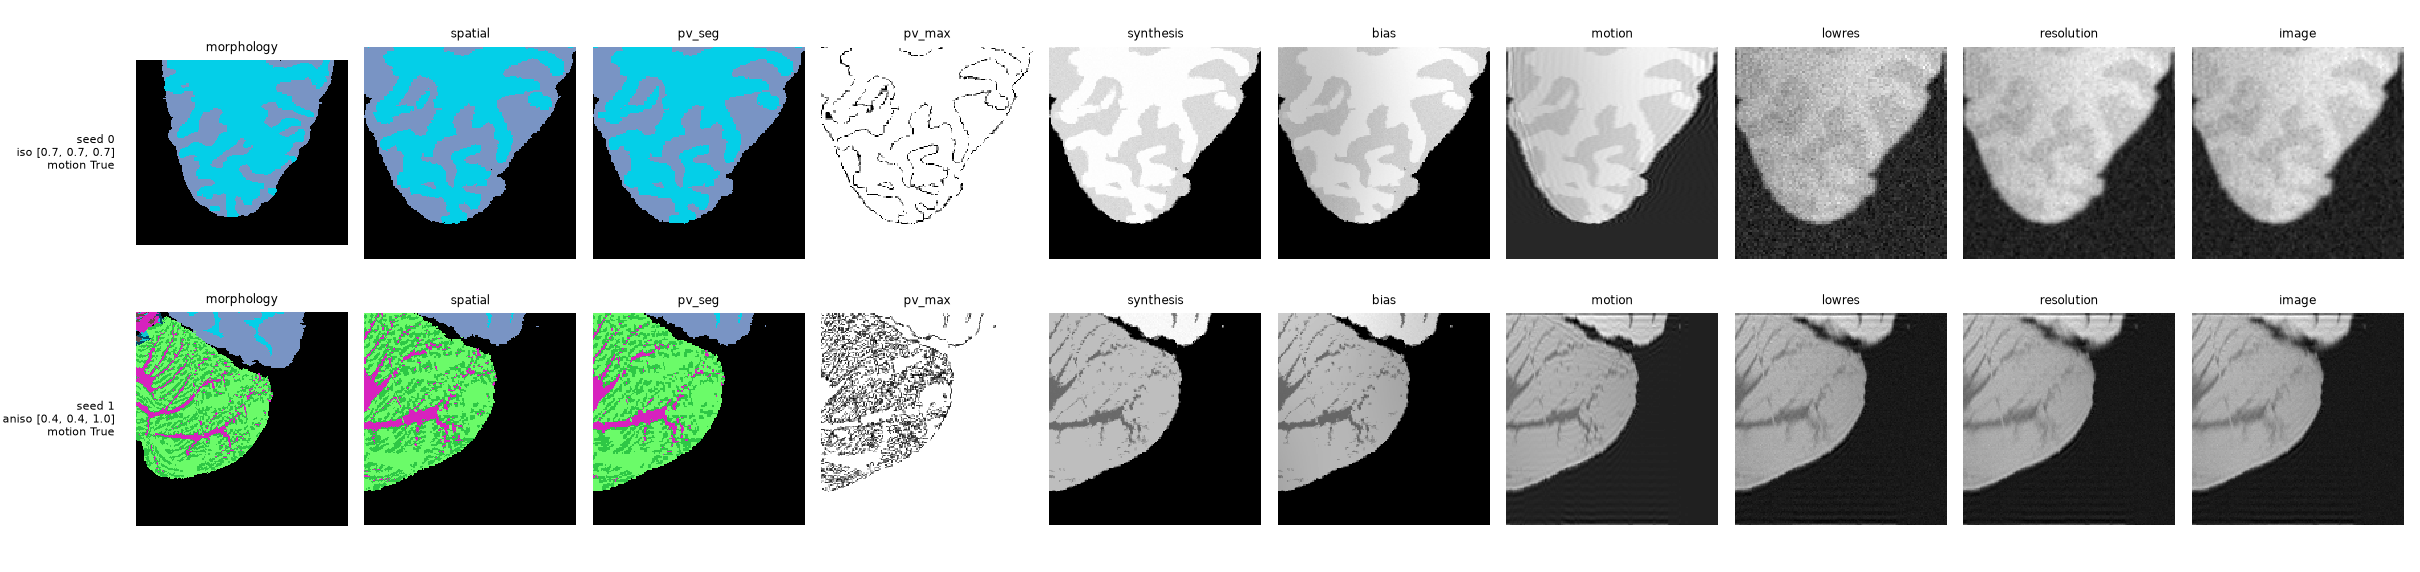

In [7]:
fig_path = os.path.join(OUTPUTS, 'steps_notebook.png')
r = subprocess.run([PY, 'examples/plot_steps.py', '--templates', TEMPLATE_DIR, '--config', CONFIG_PATCH,
                    '--device', DEVICE, '--seeds', '0', '1', '--worst-case', '--out', fig_path],
                   cwd=ROOT, capture_output=True, text=True)
print(r.stdout, r.stderr[-500:])
from IPython.display import Image
Image(fig_path)